# Predict the content formats each subscriber will use

Which subscribers will read articles, listen to audio, or watch video in the next 30 days? Train a local Kumo Engine model on generated synthetic relational data, then score newly added records.

Use a Linux notebook kernel with CPU compute and writable local scratch. Complete [Linux deployment setup](https://docs.nvidia.com/sdgm/kumo-engine/get-started-with-kumo-engine/installation/linux-machine-deployment).
This example follows [the multilabel classification workflow](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/code-examples/linux-deployment/multilabel-classification).


## Install

Install the Engine SDK and the data libraries used by this notebook.


In [ ]:
%pip install -q kumo-engine pandas numpy pyarrow


## Import the local Engine APIs

Use the local Engine graph, query, and trainer APIs in the prepared notebook kernel.


In [1]:
import json
import os
from pathlib import Path
from tempfile import mkdtemp

import numpy as np
import pandas as pd
from IPython.display import display
import kumo.engine as kumo
from kumo.engine.trainer.output_config import ModelOutputConfig, PredictionOutputConfig, TrainingTableOutputConfig
from kumoapi.graph import Edge
from kumoapi.jobs import MetadataField, PredictionArtifactType
from kumoapi.model_plan import RunMode, TrainingTableGenerationPlan
from kumoapi.typing import Dtype, Stype


/tmp/kumo-notebook-runtime/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Set the example parameters

Scratch defaults to `kumo_scratch` under the current directory; set `KUMO_SCRATCH` to use another writable local directory. Each run gets its own scratch and retained output directories. Times are timezone-naive UTC.
Leave `SMOKE_MODE=False` for the FAST tutorial plan; smoke mode caps training at one epoch and does not measure model quality.


In [2]:
SCRATCH_PARENT = Path(os.environ.get("KUMO_SCRATCH", str(Path.cwd() / "kumo_scratch"))).expanduser().resolve()
OUTPUT_PARENT = Path.cwd() / "kumo_example_runs"
RANDOM_SEED = 42
AS_OF = pd.Timestamp("2025-01-01")
SMOKE_MODE = False
NUM_CLASSES_TO_RETURN = 3

SCRATCH_PARENT.mkdir(parents=True, exist_ok=True)
if not SCRATCH_PARENT.is_dir():
    raise ValueError("KUMO_SCRATCH must point to a writable local directory.")
OUTPUT_PARENT.mkdir(parents=True, exist_ok=True)
run_dir = Path(mkdtemp(prefix="synthetic_content_format_preferences-", dir=OUTPUT_PARENT))
scratch_dir = Path(mkdtemp(prefix="synthetic_content_format_preferences-", dir=SCRATCH_PARENT))
source_dir = run_dir / "source"
output_dir = run_dir / "output"
source_dir.mkdir()
output_dir.mkdir()
kumo.configure(scratch_dir=scratch_dir)
destination = kumo.FileConnector(root_dir=str(output_dir))
print("Retained run:", run_dir)
print("Scratch:", scratch_dir)


Retained run: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_content_format_preferences/20261109T183812Z/kumo_example_runs/synthetic_content_format_preferences-2d7aq38n
Scratch: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_content_format_preferences/20261109T183812Z/kumo_scratch/synthetic_content_format_preferences-mave5w_k


## Generate synthetic example data

Create subscribers, content items, and timestamped engagement events. Subscribers have persistent but noisy format preferences, and a future window may contain zero, one, or several formats.
Run the next cell to generate the history and a separate batch reserved for scoring. You can skim the generation code; the Kumo workflow starts below.


In [3]:
rng = np.random.default_rng(RANDOM_SEED)
FORMATS = ["article", "audio", "video"]
content = pd.DataFrame({"content_id": np.arange(1, 91, dtype=np.int64),
    "format": np.repeat(FORMATS, 30), "topic": np.tile(["science", "culture", "travel"], 30)})

def make_subscribers_and_events(first_id, count, start, end, first_event):
    subscribers = pd.DataFrame({"subscriber_id": np.arange(first_id, first_id + count, dtype=np.int64),
        "plan": rng.choice(["basic", "plus"], count),
        "signup_channel": rng.choice(["web", "app"], count)})
    records = []
    days = (pd.Timestamp(end) - pd.Timestamp(start)).days
    for subscriber in subscribers.itertuples(index=False):
        preference = rng.dirichlet([0.5, 0.5, 0.5])
        rate = 0.055 if subscriber.plan == "basic" else 0.13
        for day in np.flatnonzero(rng.random(days) < rate):
            format_name = str(rng.choice(FORMATS, p=preference))
            item = int(rng.choice(content.loc[content.format.eq(format_name), "content_id"]))
            records.append((first_event + len(records), subscriber.subscriber_id, item, format_name,
                            pd.Timestamp(start) + pd.Timedelta(days=int(day), hours=12)))
    events = pd.DataFrame(records, columns=["event_id", "subscriber_id", "content_id", "format", "engaged_at"])
    return subscribers, events

subscribers, events = make_subscribers_and_events(1, 600, "2024-01-01", AS_OF, 1)
new_subscribers, new_events = make_subscribers_and_events(
    601, 40, AS_OF - pd.Timedelta(days=60), AS_OF, int(events.event_id.max()) + 1)
assert events.event_id.is_unique
assert events.subscriber_id.isin(subscribers.subscriber_id).all()
assert events.content_id.isin(content.content_id).all()
assert events.engaged_at.lt(AS_OF).all() and new_events.engaged_at.lt(AS_OF).all()
for name, frame in {"subscribers": subscribers, "content": content, "events": events}.items():
    (source_dir / name).mkdir()
    frame.to_parquet(source_dir / name / "history.parquet", index=False)
display(events.head())
print(events.groupby("format").size().rename("historical_events"))


/tmp/ipykernel_1318806/334564034.py:19: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.Timestamp(start) + pd.Timedelta(days=int(day), hours=12)))


/tmp/ipykernel_1318806/334564034.py:25: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  601, 40, AS_OF - pd.Timedelta(days=60), AS_OF, int(events.event_id.max()) + 1)


,event_id,subscriber_id,content_id,format,engaged_at
0,1,1,58,audio,2024-01-12 12:00:00
1,2,1,49,audio,2024-01-25 12:00:00
2,3,1,46,audio,2024-01-27 12:00:00
3,4,1,46,audio,2024-02-04 12:00:00
4,5,1,65,video,2024-02-08 12:00:00


format
article    6642
audio      7057
video      6461
Name: historical_events, dtype: int64


## Build the graph

Connect each engagement to its subscriber and content item. The event’s format is an ordinary categorical target; content IDs remain graph relationships.
See [tables and relationships](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs).


In [4]:
files = kumo.FileConnector(root_dir=str(source_dir))
subscriber_table = kumo.Table.from_source_table(files["subscribers"], primary_key="subscriber_id")
for column in ("plan", "signup_channel"):
    subscriber_table = subscriber_table.with_column(column, stype=Stype.categorical)
content_table = kumo.Table.from_source_table(files["content"], primary_key="content_id")
for column in ("format", "topic"):
    content_table = content_table.with_column(column, stype=Stype.categorical)
event_table = (kumo.Table.from_source_table(files["events"], primary_key="event_id", time_column="engaged_at")
    .with_column("engaged_at", dtype=Dtype.date)
    .with_column("subscriber_id", stype=Stype.ID)
    .with_column("content_id", stype=Stype.ID)
    .with_column("format", stype=Stype.categorical))
graph = kumo.Graph(tables={"subscribers": subscriber_table, "content": content_table, "events": event_table},
    edges=[Edge("events", "subscriber_id", "subscribers"), Edge("events", "content_id", "content")])
graph.validate()


## Inspect the graph

Inspect the actual graph's tables and relationships before training with [graph visualization](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs#visualize-table-relationships).
The table also lists each declared foreign-key relationship.


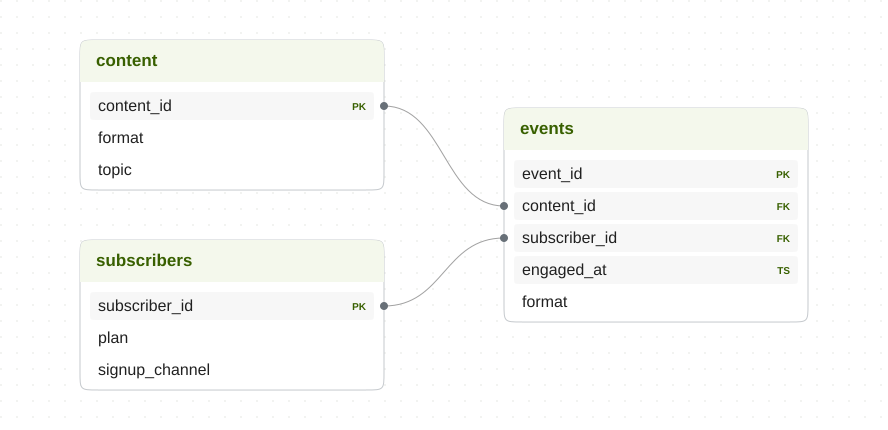

,source,foreign_key,destination
0,events,subscriber_id,subscribers
1,events,content_id,content


In [5]:
display(graph.visualize(show_cols=True))
display(pd.DataFrame([{"source": edge.src_table, "foreign_key": edge.fkey,
                       "destination": edge.dst_table} for edge in graph.edges]))


## Materialize the graph

Build a snapshot of the historical source files for training.


In [6]:
snapshot = graph.snapshot()
print("Training snapshot:", snapshot.id)


/tmp/ipykernel_1318806/3370640593.py:1: UserWarning: The kumo.engine scratch directory /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_content_format_preferences/20261109T183812Z/kumo_scratch/synthetic_content_format_preferences-mave5w_k is on Amazon EBS. Graph sampling and training-table generation read it randomly and run much slower there; local NVMe is recommended.
  snapshot = graph.snapshot()


ingest: table started phase="encode" table=subscribers


ingest: table producers complete phase="encode" table=subscribers rows=600 elapsed_ms=1


ingest: Ingestion stage progress phase=Encode table=subscribers shard=None progress_pct=100 current=1 total=1


ingest: table started phase="encode" table=content


ingest: table producers complete phase="encode" table=content rows=90 elapsed_ms=0


... (16 outputs left out)

ingest: finalize stage complete stage="finalize" elapsed_ms=0 elapsed=0ms


diskgraph ingest succeeded after 1 attempt(s) at 5 threads


diskgraph ingest completed: 3 node tables, 4 edge relations, 20850 nodes, 80640 edges


Training snapshot: 738c07d3935494da12f1ffa3f0419280ad0c6cc1b3163fc9a7e9df9137f26595@0ce475ed020fb565


## Define the prediction task

Collect distinct formats in `(anchor, anchor + 30 days]`. `CLASSIFY TOP 3` describes three possible labels; a subscriber may use several formats, so this is multilabel classification.
Validate the [predictive query](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/predictive-queries) before generating labels.


In [7]:
QUERY = 'PREDICT LIST_DISTINCT(events.format, 0, 30, days) CLASSIFY TOP 3 FOR EACH subscribers.subscriber_id'
query = kumo.PredictiveQuery(graph, QUERY)
query.validate()
assert query.get_task_type() == 'multilabel_classification'
print(QUERY)
print("Task:", query.get_task_type())


PREDICT LIST_DISTINCT(events.format, 0, 30, days) CLASSIFY TOP 3 FOR EACH subscribers.subscriber_id
Task: multilabel_classification


## Generate training rows and inspect the splits

Use an approximate chronological 70/15/15 split so validation and test follow training. Use the most recent 300 days of history, with anchors 30 days apart. ApproxDateOffsetSplit separates label windows across splits; the latest anchor leaves 30 days of observed outcomes. Inspect the actual split sizes below.
Export the [training table](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/training-tables) to inspect its actual splits: `0` is training, `1` validation, and `2` test. `ENTITY1` identifies the entity, `TIMESTAMP` its anchor, and `TARGET1` the outcome.


In [8]:
generation_plan = TrainingTableGenerationPlan(
    split="ApproxDateOffsetSplit([0.7, 0.15, 0.15])",
train_start_offset=300, train_end_offset=0, timeframe_step=30,
)
training_table = query.generate_training_table(snapshot, plan=generation_plan)
training_table.export(TrainingTableOutputConfig(connector=destination, table_name="training_rows/"))
training_rows = pd.read_parquet(output_dir / "training_rows")
display(training_rows.head(8))
display(training_rows.groupby("SPLIT").agg(rows=("ENTITY1", "size"),
    first_anchor=("TIMESTAMP", "min"), last_anchor=("TIMESTAMP", "max")))
assert set(training_rows.SPLIT) == {0, 1, 2}


,ENTITY1,TIMESTAMP,TARGET1,SPLIT
0,451,2024-03-06 12:00:00,article,0
1,451,2024-04-05 12:00:00,audio|video,0
2,451,2024-05-05 12:00:00,video|article,0
3,451,2024-06-04 12:00:00,audio,0
4,451,2024-07-04 12:00:00,audio|video|article,0
5,451,2024-08-03 12:00:00,video|audio,0
6,451,2024-09-02 12:00:00,video|audio|article,0
7,452,2024-03-06 12:00:00,audio,0


,rows,first_anchor,last_anchor
SPLIT,,,
0,4200,2024-03-06 12:00:00,2024-09-02 12:00:00
1,1200,2024-10-02 12:00:00,2024-11-01 12:00:00
2,600,2024-12-01 12:00:00,2024-12-01 12:00:00


## Configure the model

Start from the supported [FAST plan](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/training). Keep the task-specific metrics selected by Engine and inspect the tuning metric below.
Disable refitting to keep validation and test separate from the fitted training population.


In [9]:
plan = query.suggest_model_plan(snapshot, run_mode=RunMode.FAST)
plan.training_job.refit_trainval = False
plan.training_job.refit_full = False

if SMOKE_MODE:
    plan.training_job.num_experiments = 1
    plan.optimization.max_epochs = 1
    print("Smoke mode: pipeline check only")
(output_dir / "model_plan.json").write_text(json.dumps(plan.as_json(), indent=2) + "\n")
print("Tuning metric:", plan.training_job.tune_metric)
print("Maximum epochs:", plan.optimization.max_epochs)


Tuning metric: ap_macro
Maximum epochs: 8


## Train and retain the model

Fit on the generated training rows and export the complete model bundle for reuse.


In [10]:
trainer = kumo.Trainer(plan, accelerator="cpu")
fit_result = trainer.fit(training_table, snapshot=snapshot,
    export_config=ModelOutputConfig(connector=destination, path="model"))
print("Saved model:", output_dir / "model")


[I 2026-11-09 18:38:22,593] A new study created in memory with name: no-name-3087fbc4-bd8f-4cdd-8dad-a45a394255dc


GPU available: False, used: False


TPU available: False, using: 0 TPU cores



  | Name           | Type                          | Params | Mode  | FLOPs
---------------------------------------------------------------------------------
0 | target_encoder | MultiCategoricalTargetEncoder | 0      | train | 0    
1 | metric_store   | MetricStore                   | 0      | train | 0    
2 | loss           | BinaryCrossEntropyLoss        | 0      | train | 0    
3 | calibrator     | PlatScaling                   | 2      | train | 0    
4 | encoder        | HeteroTensorFrameEncoder      | 6.3 K  | train | 0    
5 | model          | HeteroGNN                     | 104 K  | train | 0    
6 | head           | NodePredHead                  | 4.5 K  | train | 0    
---------------------------------------------------------------------------------
115 K     Trainable params
0         Non-trainable params
115 K     Total params
0.462     Total estimated model params size (MB)
173       Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

... (172 outputs left out)

Testing DataLoader 0: 100%|██████████| 2/2 [00:03<00:00,  0.50it/s]

Testing DataLoader 0: 100%|██████████| 2/2 [00:04<00:00,  0.44it/s]


────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_loss           0.5901308655738831
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


Saved model: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_content_format_preferences/20261109T183812Z/kumo_example_runs/synthetic_content_format_preferences-2d7aq38n/output/model


## Evaluate

**Synthetic-data metrics - demonstration only.** Review the fit's metrics to check that the workflow learned from the generated patterns. Macro average precision gives each format equal weight; per-label metrics show whether one format is harder to predict.
These are the fit's reported metrics; choose settings using validation and reserve test results for final assessment.


In [11]:
print("Synthetic-data metrics — demonstration only")
display(pd.Series(fit_result.metrics, name="value").rename_axis("metric").to_frame())
(output_dir / "metrics.json").write_text(json.dumps(fit_result.metrics, indent=2, default=float) + "\n")


Synthetic-data metrics — demonstration only


,value
metric,
val_loss,0.470302
val_ap_macro,0.835289
val_ap_micro,0.832554
val_auprc_macro,0.835073
val_auprc_micro,0.832466
val_auroc_macro,0.858296
val_auroc_micro,0.857812
test_loss,0.474515
test_ap_macro,0.837314


1309

## Batch predictions

Add 40 new subscribers and their observed engagement histories. All new events precede the scoring anchor, so their future format labels are unknown. Write the new rows as additional Parquet parts in the existing table directories. A new snapshot reads those parts while the training snapshot remains unchanged.


In [12]:
assert set(new_subscribers.subscriber_id).isdisjoint(subscribers.subscriber_id)
new_subscribers.to_parquet(source_dir / "subscribers" / "new.parquet", index=False)
new_events.to_parquet(source_dir / "events" / "new.parquet", index=False)
scoring_population = pd.DataFrame({"ENTITY1": new_subscribers.subscriber_id, "TIMESTAMP": AS_OF})
assert not any(column.startswith("TARGET") for column in scoring_population)
assert len(scoring_population) == 40 and not scoring_population.duplicated(["ENTITY1", "TIMESTAMP"]).any()
scoring_population.to_parquet(source_dir / "scoring_population.parquet", index=False)
scoring_snapshot = graph.snapshot()
assert scoring_snapshot.id != snapshot.id
display(scoring_population.head())


ingest: table started phase="encode" table=subscribers


ingest: table producers complete phase="encode" table=subscribers rows=640 elapsed_ms=3


ingest: Ingestion stage progress phase=Encode table=subscribers shard=None progress_pct=100 current=1 total=1


ingest: table started phase="encode" table=content


ingest: table producers complete phase="encode" table=content rows=90 elapsed_ms=1


ingest: Ingestion stage progress phase=Encode table=content shard=None progress_pct=100 current=1 total=1


... (15 outputs left out)

ingest: finalize stage complete stage="finalize" elapsed_ms=0 elapsed=0ms


diskgraph ingest succeeded after 1 attempt(s) at 5 threads


diskgraph ingest completed: 3 node tables, 4 edge relations, 21113 nodes, 81532 edges


,ENTITY1,TIMESTAMP
0,601,2025-01-01
1,602,2025-01-01
2,603,2025-01-01
3,604,2025-01-01
4,605,2025-01-01


### Prepare the scoring population

Use a [custom prediction table](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/making-predictions) containing only the 40 new entity IDs and their anchor times. This keeps historical training entities out of the scoring batch.


In [13]:
prediction_table = kumo.PredictionTable.from_source_table(
    files["scoring_population"], pq=query, snapshot=scoring_snapshot, plan=generation_plan)
generated_population = pd.read_parquet(prediction_table.table_path)
assert set(generated_population.ENTITY1) == set(scoring_population.ENTITY1)
assert len(generated_population) == len(scoring_population)
display(generated_population.head())


,ENTITY1,TIMESTAMP
0,601,2025-01-01
1,602,2025-01-01
2,603,2025-01-01
3,604,2025-01-01
4,605,2025-01-01


### Score the new records

Run the trained model on the new snapshot and save predictions, including anchor timestamps, as Parquet.


In [14]:
prediction_result = trainer.predict(
    prediction_table, snapshot=scoring_snapshot,
    num_classes_to_return=NUM_CLASSES_TO_RETURN,
    output_config=PredictionOutputConfig(connector=destination,
        artifact_type=PredictionArtifactType.PREDICTIONS, table_name="predictions.parquet",
        extra_fields=[MetadataField.ANCHOR_TIMESTAMP]),
)
scores = prediction_result.frame


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


Restoring states from the checkpoint path at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_content_format_preferences/20261109T183812Z/kumo_scratch/synthetic_content_format_preferences-mave5w_k/trainers/2495630557264dfcaac3c627f29bbaaf/runs/2495630557264dfcaac3c627f29bbaaf-predict-7711c91085c74f57b2798642ebcd0af2/model_bundle/model/checkpoint/step=0.ckpt


Loaded model weights from the checkpoint at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_content_format_preferences/20261109T183812Z/kumo_scratch/synthetic_content_format_preferences-mave5w_k/trainers/2495630557264dfcaac3c627f29bbaaf/runs/2495630557264dfcaac3c627f29bbaaf-predict-7711c91085c74f57b2798642ebcd0af2/model_bundle/model/checkpoint/step=0.ckpt


Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 39.79it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 29.88it/s]

### Inspect and verify the results

`ENTITY` is the new record ID and `ANCHOR_TIMESTAMP` its scoring time. Expect three rows per subscriber, one per `CLASS` (format). `SCORE` is a per-format probability and `PREDICTED` its model decision; several labels can be selected and probabilities need not sum to one. No explicit binary threshold is passed. Verify IDs and times together, not row order.


In [15]:
expected = scoring_population.rename(columns={"ENTITY1": "ENTITY", "TIMESTAMP": "ANCHOR_TIMESTAMP"})
expected["ANCHOR_TIMESTAMP"] = pd.to_datetime(expected.ANCHOR_TIMESTAMP)
scores["ANCHOR_TIMESTAMP"] = pd.to_datetime(scores.ANCHOR_TIMESTAMP)

assert not scores.duplicated(["ENTITY", "ANCHOR_TIMESTAMP", "CLASS"]).any()
keys = scores[["ENTITY", "ANCHOR_TIMESTAMP"]].drop_duplicates()
aligned = expected.merge(keys, how="outer", validate="one_to_one", indicator=True)
assert aligned._merge.eq("both").all()
assert scores.groupby(["ENTITY", "ANCHOR_TIMESTAMP"]).size().eq(NUM_CLASSES_TO_RETURN).all()
assert np.isfinite(scores.SCORE.to_numpy()).all()

assert scores.SCORE.between(0, 1).all()
assert all(set(group.CLASS) == set(FORMATS) for _, group in scores.groupby("ENTITY"))
assert scores.PREDICTED.isin([True, False]).all()
display(scores[["ENTITY", "ANCHOR_TIMESTAMP", "CLASS", "SCORE", "PREDICTED"]].head(12))
pd.testing.assert_frame_equal(scores, pd.read_parquet(output_dir / "predictions.parquet"))
print("Saved predictions:", output_dir / "predictions.parquet")


,ENTITY,ANCHOR_TIMESTAMP,CLASS,SCORE,PREDICTED
0,601,2025-01-01,video,0.909098,True
1,601,2025-01-01,article,0.475358,False
2,601,2025-01-01,audio,0.415723,False
3,603,2025-01-01,article,0.808076,True
4,603,2025-01-01,audio,0.693307,True
5,603,2025-01-01,video,0.490263,False
6,605,2025-01-01,video,0.918284,True
7,605,2025-01-01,audio,0.583288,True
8,605,2025-01-01,article,0.142658,False
9,607,2025-01-01,video,0.523528,True


Saved predictions: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_content_format_preferences/20261109T183812Z/kumo_example_runs/synthetic_content_format_preferences-2d7aq38n/output/predictions.parquet


## Retain and reuse

Reload the complete trusted model bundle without fitting again. Keep the source tables and compatible graph schema alongside the bundle; the model does not contain graph data.
A later process must configure scratch, rebuild the graph and snapshot, and prepare its scoring table. See [publish and retrieve models](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/publish-and-retrieve-models).


In [16]:
reloaded_trainer = kumo.Trainer.load(output_dir / "model", accelerator="cpu")
print("Reloaded model from:", output_dir / "model")
print("Retain this run directory:", run_dir)


Reloaded model from: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_content_format_preferences/20261109T183812Z/kumo_example_runs/synthetic_content_format_preferences-2d7aq38n/output/model
Retain this run directory: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_content_format_preferences/20261109T183812Z/kumo_example_runs/synthetic_content_format_preferences-2d7aq38n


## Cleanup

Keep the generated inputs, model, and predictions under `run_dir`. After scoring and reload checks, optionally remove only this run's scratch directory; rebuild snapshots before further prediction.


In [17]:
import shutil

REMOVE_RUN_SCRATCH = False
if REMOVE_RUN_SCRATCH:
    shutil.rmtree(scratch_dir)
    print("Removed run scratch:", scratch_dir)
